# EDuPlane — Benchmarks & Results for 2026 TAES paper

This notebook reproduces figures, plots and experimental analysis of a set of trajectory generation algorithms based on the Dubins airplane method,
as presented in the paper

> S. Schopferer (2026) **Extensions to the Dubins Airplane Method - Flight Performance Constraints in Uniform Wind**  
> (accepted for publication in IEEE TAES, preprint available at [https://arxiv.org/abs/2611.08004])

The notebook may also serve as an entry point to explore the `EduPlane` software package.

**Kernel:** select the `EDuPlane` project virtual env as the notebook kernel. This was tested with Python 3.14.4.  
**Version Compatibilty:** developed for and tested with version tagged `TAES_2026`

---

In [77]:
# General setup and initialization

# Setup auto-reload of imported modules
%load_ext autoreload
%autoreload 2

# Find repository root and add to system PATH to be able to import modules from the `EDuPlane` package
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print("Repo root:", REPO_ROOT)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Repo root: /home/simon/sync/Promotion/Code/ExtDubinsAirplane


## Chapter 1 - Plots

Reproduces figures from the above listed paper.

In [98]:
# Imports and plotting configuration
import math
import unittest
import subprocess
import shutil
import copy
import matplotlib.pyplot as plt

from tests.solver.test_tools import Sample2D, Sample3D, get_aircraft_model
from eduplane.solver.dubins_path import get_dubins_path_3D
from eduplane.solver.trochoid_path import (
    get_trochoid_path_2D, 
    get_trochoid_path_3D_const_thrust, 
    get_trochoid_path_3D_const_vert_speed,
    get_trochoid_path_3D_longitudinal_transition,
)
from eduplane.utils import utils, plotting
from eduplane.traj import Trajectory, LiftedSegment

check = unittest.TestCase()     # for unittest assertion functions

SHOW_PLOTS = True
SAVE_PLOTS = True
CROP_PLOTS = shutil.which("pdfcrop") is not None

plotting.configure(mode="latex", pageformat="IEEE_single_column")
#plotting.configure(mode="screen")

Creating 2 timeline plots for trajectory 'traj. #0'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `dubins_path_csc3d_constrained_vert_speed.cropped.pdf'.


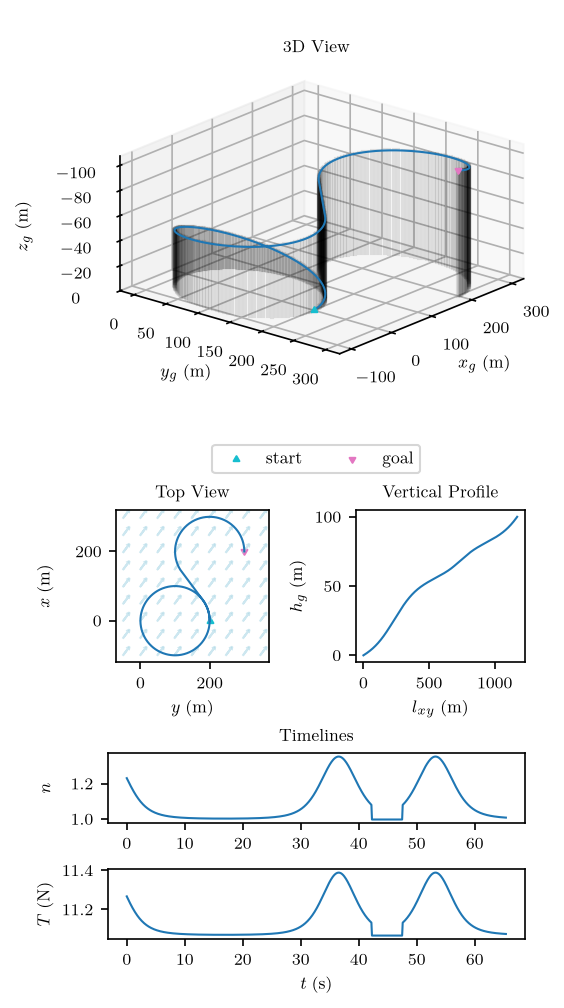

In [79]:
# 3D Dubins path with circular turns in uniform wind with constant (and constrained) vertical speed

def plot_csc3d_dubins_constrained_vert_speed():
    turn_radius_m = 100
    airspeed_mps = 20
    wind_speed = 10
    wind_dir = math.pi*0.25
    start = Sample3D(0, 200, 0, 0)
    goal = Sample3D(200, 300, -100, math.pi)
    path_type = "LSR"
    vs_constraint = lambda w_A_g: abs(w_A_g) < 2

    path = get_dubins_path_3D(
        start_x=start.x_g,
        start_y=start.y_g,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g,
        goal_y=goal.y_g,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=airspeed_mps,
        turn_radius=turn_radius_m,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        vert_speed_constraint=vs_constraint)
    check.assertIsNotNone(
        path, msg=f"Failed to plan {path_type} path from {start} to {goal}")
    path_discr = path.discretize()
    path_discr.check_kinematic_consistency(1, 1, 0, 1, raise_err=True)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
    check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=3)
    check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g)
    check.assertAlmostEqual(path_discr.xf["y_g"], goal.y_g, places=3)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
        0.0,
        places=3)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
        0.0,
        places=3)
    # Plot the results
    POIs = [
        dict(
            x_g=start.x_g,
            y_g=start.y_g,
            z_g=start.z_g,
            # chi=start.chi,
            label="start",
            # style="go",
            s=10,
            marker=(3, 0, math.degrees(start.chi)),
            color="tab:cyan",
        ),
        dict(
            x_g=goal.x_g,
            y_g=goal.y_g,
            z_g=goal.z_g,
            # chi=goal.chi,
            label="goal",
            # style="gx",
            s=10,
            marker=(3, 0, math.degrees(goal.chi)),
            color="tab:pink",
        ),
    ]

    # Calculate thrust, load factor etc.
    ac = get_aircraft_model()
    ac.fly_trajectory(path_discr)

    # Create plot
    fig, ax = plotting.plot_ref_trajectory(
        paths=path_discr.df,
        POIs=POIs,
        s_col=None,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        timelines=["n", "T"])

    if SAVE_PLOTS:
        # Fine-tune and save
        fig.canvas.draw()
        fig.savefig("dubins_path_csc3d_constrained_vert_speed.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0",
                    "dubins_path_csc3d_constrained_vert_speed.pdf",
                    "dubins_path_csc3d_constrained_vert_speed.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_csc3d_dubins_constrained_vert_speed()
plt.show()

PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `trochoid_path_csca.cropped.pdf'.


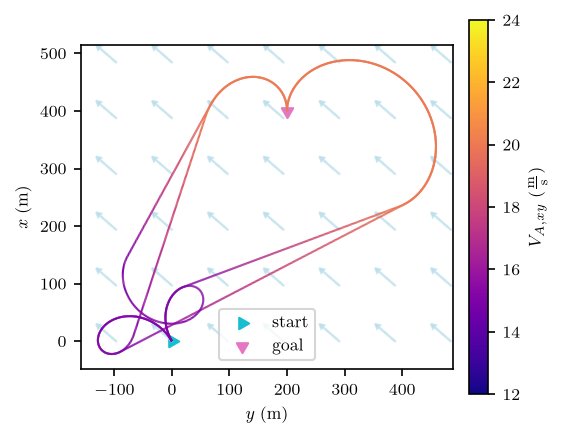

In [99]:
# 2D Dubins path with asymmetric trochoidal turns and accelerated linear segment in uniform wind

def plot_trochoid_path_csca():

    # Horizontal CSCA path
    # =========================================
    airspeed_1 = 15
    airspeed_2 = 20
    wind_speed = 5
    wind_dir = -math.pi*0.25
    turn_rate_1 = airspeed_1/50
    turn_rate_2 = airspeed_2/100

    # Create a start and a set of goal points
    start = Sample2D(0, 0, math.radians(-30))
    goal = Sample2D(400, 200, math.radians(180))

    path_types = ["LSL", "RSR", "RSL", "LSR"]

    # Test computation of all the path types
    discr_paths = []
    for path_type in path_types:
        path = get_trochoid_path_2D(
            start_x=start.x_g,
            start_y=start.y_g,
            start_dir=start.chi,
            goal_x=goal.x_g,
            goal_y=goal.y_g,
            goal_dir=goal.chi,
            airspeed=(airspeed_1, airspeed_2),
            turn_rate=(turn_rate_1, turn_rate_2),
            wind_speed=wind_speed,
            wind_dir=wind_dir,
            path_type=path_type)
        check.assertIsNotNone(
            path,
            msg=f"Failed to plan {path_type} path "
            f"from {start} to {goal}")
        path_discr = path.discretize()
        path_discr.check_kinematic_consistency(
            1, 1, 0, 1, raise_err=True, abs_err_threshold=1e-6)
        # Check initial and final state
        check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
        check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=0)
        check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g)
        check.assertAlmostEqual(path_discr.xf["y_g"], goal.y_g, places=0)
        check.assertAlmostEqual(
            abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
            0.0,
            places=2)
        check.assertAlmostEqual(
            abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
            0.0,
            places=2)

        # Store all paths for plotting
        discr_paths.append(path_discr)

    # Plot the results
    POIs = [
        dict(
            x_g=start.x_g,
            y_g=start.y_g,
            # chi=start.chi,
            label="start",
            s=40,
            color="tab:cyan",
            # style="go",
            marker=(3, 0, math.degrees(start.chi + math.pi))),
        dict(
            x_g=goal.x_g,
            y_g=goal.y_g,
            # chi=goal.chi,
            label="goal",
            s=40,
            color="tab:pink",
            # style="gx",
            marker=(3, 0, math.degrees(goal.chi)))
    ]

    fig, ax = plotting.plot_topview(
        trajs=[p.df for p in discr_paths],
        POIs=POIs,
        s_col="V_A_xy",
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        title=False)
    # ax["T"].set_ylim(-1, 5)

    if SAVE_PLOTS:
        fig.canvas.draw()
        fig.savefig("trochoid_path_csca.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0", "trochoid_path_csca.pdf",
                    "trochoid_path_csca.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_trochoid_path_csca()
plt.show()

Creating 2 timeline plots for trajectory 'continuous turns'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
Creating 2 timeline plots for trajectory 'periodic paths'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `trochoid_path_csc3d_const_vert_speed.cropped.pdf'.


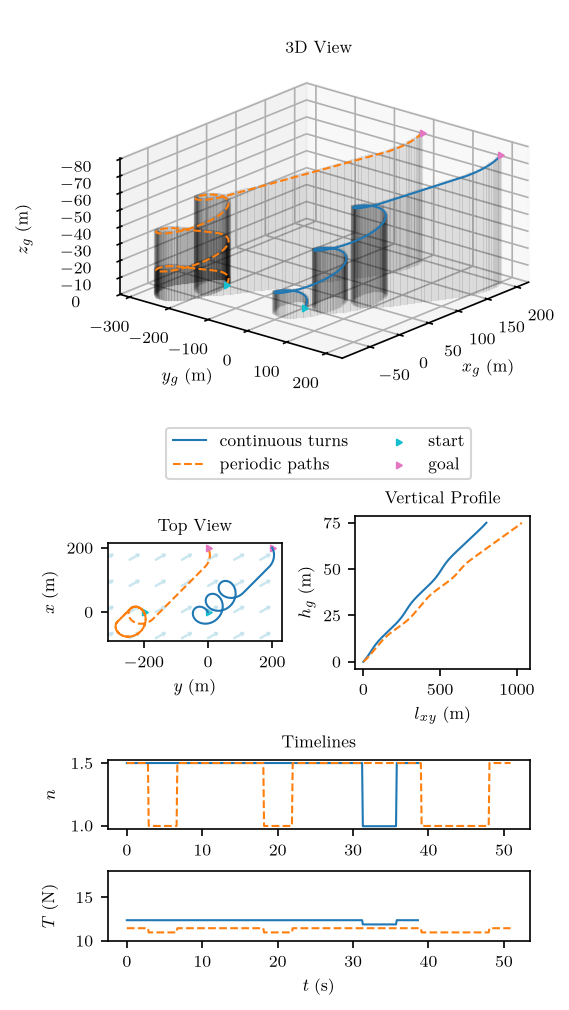

In [81]:
# 3D Dubins path with trochoidal turns in uniform wind with constant (and constrained) vertical speed

def plot_trochoid_path_3D_const_vert_speed():
    airspeed_1 = 20
    airspeed_2 = 20
    wind_speed = 5
    wind_dir = math.pi*0.25
    turn_n_max = 1.5
    # Create a start and a set of goal points
    start = Sample3D(0, 0, 0, math.radians(-30))
    goal = Sample3D(200, 200, -75, math.radians(-30))
    path_type = "LSL"
    discr_paths = []

    ac = get_aircraft_model()

    # Path will full turns
    # ====================
    path = get_trochoid_path_3D_const_vert_speed(
        start_x=start.x_g,
        start_y=start.y_g,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g,
        goal_y=goal.y_g,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=(airspeed_1, airspeed_2),
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        vert_speed_constraint=lambda w: abs(w) < 2,
        high_alt_strategy="full turns")
    check.assertIsNotNone(
        path,
        msg=f"Failed to plan {path_type} path "
        f"from {start} to {goal}")
    path_discr = path.discretize()
    path_discr.check_kinematic_consistency(
        1, 1, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
    check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=2)
    check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g)
    check.assertAlmostEqual(path_discr.xf["y_g"], goal.y_g, places=2)
    check.assertAlmostEqual(path_discr.x0["z_g"], start.z_g)
    check.assertAlmostEqual(path_discr.xf["z_g"], goal.z_g, places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
        0.0,
        places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
        0.0,
        places=2)
    ac.fly_trajectory(path_discr)
    discr_paths.append(path_discr)

    # Path with periodic path
    # ====================
    periodic_path_y_offset = -200
    path = get_trochoid_path_3D_const_vert_speed(
        start_x=start.x_g,
        start_y=start.y_g + periodic_path_y_offset,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g,
        goal_y=goal.y_g + periodic_path_y_offset,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=(airspeed_1, airspeed_2),
        # turn_rate=(turn_rate_1_radps, turn_rate_2_radps),
        # turn_n_max=None,
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        vert_speed_constraint=lambda w: abs(w) < 2,
        high_alt_strategy="periodic paths")
    check.assertIsNotNone(
        path,
        msg=f"Failed to plan {path_type} path "
        f"from {start} to {goal}")
    path_discr = path.discretize()
    path_discr.check_kinematic_consistency(
        1, 1, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
    check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=2)
    check.assertAlmostEqual(
        path_discr.x0["y_g"], start.y_g + periodic_path_y_offset)
    check.assertAlmostEqual(
        path_discr.xf["y_g"], goal.y_g + periodic_path_y_offset, places=2)
    check.assertAlmostEqual(path_discr.x0["z_g"], start.z_g)
    check.assertAlmostEqual(path_discr.xf["z_g"], goal.z_g, places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
        0.0,
        places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
        0.0,
        places=2)
    ac.fly_trajectory(path_discr)
    discr_paths.append(path_discr)

    POIs = [
        dict(
            x_g=(start.x_g, start.x_g),
            y_g=(start.y_g, start.y_g + periodic_path_y_offset),
            z_g=(start.z_g, start.z_g),
            # chi=start.chi,
            label="start",
            # style="go",
            s=10,
            marker=(3, 0, math.degrees(start.chi) + 180),
            color="tab:cyan",
        ),
        dict(
            x_g=(goal.x_g, goal.x_g),
            y_g=(goal.y_g, goal.y_g + periodic_path_y_offset),
            z_g=(goal.z_g, goal.z_g),
            # chi=goal.chi,
            label="goal",
            # style="gx",
            s=10,
            marker=(3, 0, math.degrees(goal.chi) + 180),
            color="tab:pink",
        ),
    ]

    fig, ax = plotting.plot_ref_trajectory(
        paths={
            "continuous turns": discr_paths[0].df,
            "periodic paths": discr_paths[1].df,
        },
        POIs=POIs,
        s_col=None,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        timelines=["n", "T"])
    ax["T"].set_ylim(10, 18)

    if SAVE_PLOTS:
        fig.canvas.draw()
        fig.savefig("trochoid_path_csc3d_const_vert_speed.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0",
                    "trochoid_path_csc3d_const_vert_speed.pdf",
                    "trochoid_path_csc3d_const_vert_speed.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_trochoid_path_3D_const_vert_speed()
plt.show()

Creating 3 timeline plots for trajectory 'traj. #0'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #2: {'columns': ['w_A_g'], 'ylabel': 'w_A_g', 'styles': [{}], 'plot_kwargs': [{}]}
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `trochoid_path_csc3d_const_thrust.cropped.pdf'.


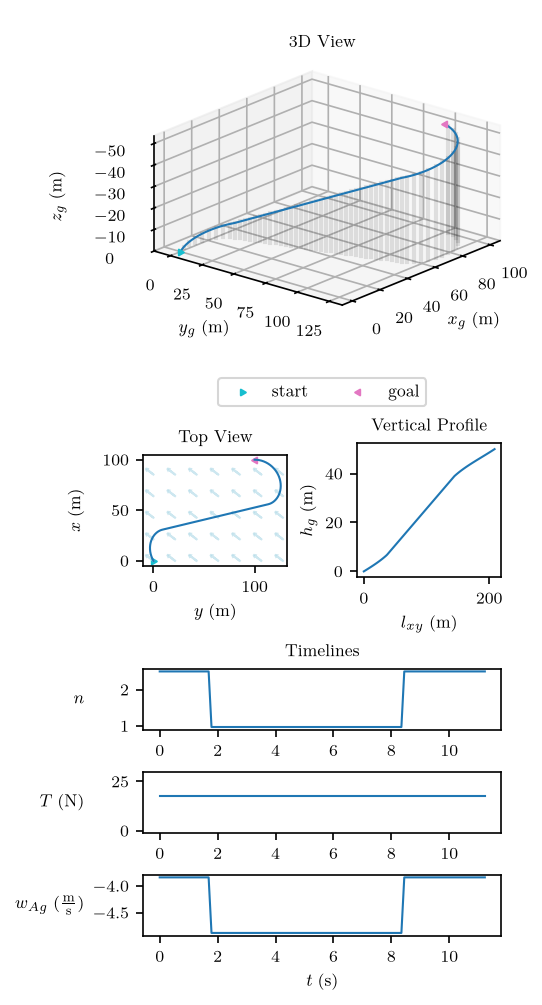

In [82]:
# 3D Dubins path with trochoidal turns in uniform wind with constant (and constrained) thrust

def plot_trochoid_path_3D_const_thrust():

    ac = get_aircraft_model()

    airspeed_1 = 20
    airspeed_2 = 20
    wind_speed = 5
    wind_dir = -math.pi*0.25
    turn_n_max = 2.5

    # Create a start and a set of goal points
    start = Sample3D(0, 0, 0, math.radians(-30))
    goal = Sample3D(100, 100, -50, math.radians(-90))

    path_type = "RSL"

    # Test computation of all the path types
    discr_paths = []
    path = get_trochoid_path_3D_const_thrust(
        start_x=start.x_g,
        start_y=start.y_g,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g,
        goal_y=goal.y_g,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=(airspeed_1, airspeed_2),
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        ac=ac,
        thrust_constraint=lambda T: T > 0 and T < 25,
        high_alt_strategy="periodic paths")
    check.assertIsNotNone(
        path,
        msg=f"Failed to plan {path_type} path "
        f"from {start} to {goal}")
    path_discr = path.discretize()
    path_discr.check_kinematic_consistency(
        1, 0, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
    check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=0)
    check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g)
    check.assertAlmostEqual(path_discr.xf["y_g"], goal.y_g, places=0)
    check.assertAlmostEqual(path_discr.x0["z_g"], start.z_g)
    check.assertAlmostEqual(path_discr.xf["z_g"], goal.z_g, places=0)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
        0.0,
        places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
        0.0,
        places=2)

    # Store all paths for plotting
    discr_paths.append(path_discr)

    # Plot the results
    plotting.configure(mode="latex", pageformat="IEEE_single_column")
    POIs = [
        dict(
            x_g=start.x_g,
            y_g=start.y_g,
            z_g=start.z_g,
            # chi=start.chi,
            label="start",
            s=10,
            color="tab:cyan",
            # style="go",
            marker=(3, 0, math.degrees(start.chi + math.pi))),
        dict(
            x_g=goal.x_g,
            y_g=goal.y_g,
            z_g=goal.z_g,
            # chi=goal.chi,
            label="goal",
            s=10,
            color="tab:pink",
            # style="gx",
            marker=(3, 0, math.degrees(goal.chi + math.pi)))
    ]

    ac.fly_trajectory(path_discr)
    fig, ax = plotting.plot_ref_trajectory(
        paths=path_discr.df,
        POIs=POIs,
        s_col=None,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        timelines=["n", "T", "w_A_g"])
    ax["T"].set_ylim(-1, 30)

    if SAVE_PLOTS:
        fig.canvas.draw()
        fig.savefig("trochoid_path_csc3d_const_thrust.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0",
                    "trochoid_path_csc3d_const_thrust.pdf",
                    "trochoid_path_csc3d_const_thrust.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_trochoid_path_3D_const_thrust()
plt.show()

Creating 3 timeline plots for trajectory 'traj. #0'
Subplot specification #0: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['V_A'], 'ylabel': 'V_A', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #2: {'columns': ['w_A_g'], 'ylabel': 'w_A_g', 'styles': [{}], 'plot_kwargs': [{}]}
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package Support Group.
==> 1 page written on `trochoid_path_csc3d_const_thrust_varspeed.cropped.pdf'.


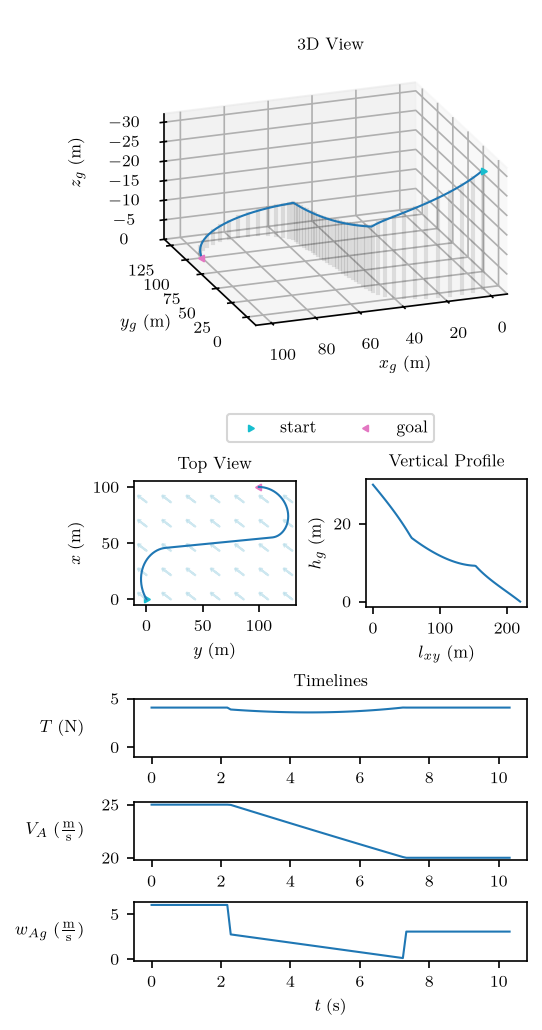

In [83]:
# 3D Dubins path with trochoidal turns in uniform wind with constrained thrust and varying airspeed linear segment


def plot_trochoid_path_3D_const_thrust_varspeed():

    ac = get_aircraft_model()

    airspeed_1 = 25
    airspeed_2 = 20
    wind_speed = 5
    wind_dir = -math.pi*0.25
    turn_n_max = 2.5

    # Create a start and a set of goal points
    start = Sample3D(0, 0, -30, math.radians(-30))
    goal = Sample3D(100, 100, 0, math.radians(-90))

    path_type = "RSL"

    # Test computation of all the path types
    discr_paths = []
    path = get_trochoid_path_3D_const_thrust(
        start_x=start.x_g,
        start_y=start.y_g,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g,
        goal_y=goal.y_g,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=(airspeed_1, airspeed_2),
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        ac=ac,
        thrust_constraint=lambda T: T > 0 and T < 25,
        high_alt_strategy="periodic paths")
    check.assertIsNotNone(
        path, msg=f"Failed to plan {path_type} path "
        f"from {start} to {goal}")
    path_discr = path.discretize()
    path_discr.check_kinematic_consistency(
        1, 0, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g)
    check.assertAlmostEqual(path_discr.xf["x_g"], goal.x_g, places=0)
    check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g)
    check.assertAlmostEqual(path_discr.xf["y_g"], goal.y_g, places=0)
    check.assertAlmostEqual(path_discr.x0["z_g"], start.z_g)
    check.assertAlmostEqual(path_discr.xf["z_g"], goal.z_g, places=0)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)), 0.0, places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)), 0.0, places=2)

    # Store all paths for plotting
    discr_paths.append(path_discr)

    # Plot the results
    plotting.configure(mode="latex", pageformat="IEEE_single_column")
    POIs = [
        dict(
            x_g=start.x_g,
            y_g=start.y_g,
            z_g=start.z_g,
            # chi=start.chi,
            label="start",
            s=10,
            color="tab:cyan",
            # style="go",
            marker=(3, 0, math.degrees(start.chi + math.pi))),
        dict(
            x_g=goal.x_g,
            y_g=goal.y_g,
            z_g=goal.z_g,
            # chi=goal.chi,
            label="goal",
            s=10,
            color="tab:pink",
            # style="gx",
            marker=(3, 0, math.degrees(goal.chi + math.pi)))
    ]

    ac.fly_trajectory(path_discr)
    fig, ax = plotting.plot_ref_trajectory(
        paths=path_discr.df,
        POIs=POIs,
        s_col=None,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        timelines=["T", "V_A", "w_A_g"])
    ax["T"].set_ylim(-1, 5)
    ax["3D view"].view_init(elev=-20, azim=290, roll=180)

    if SAVE_PLOTS:
        fig.canvas.draw()
        fig.savefig("trochoid_path_csc3d_const_thrust_varspeed.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0",
                    "trochoid_path_csc3d_const_thrust_varspeed.pdf",
                    "trochoid_path_csc3d_const_thrust_varspeed.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_trochoid_path_3D_const_thrust_varspeed()
plt.show()

Creating 4 timeline plots for trajectory 'const. thrust'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #2: {'columns': ['V_A'], 'ylabel': 'V_A', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #3: {'columns': ['w_A_g'], 'ylabel': 'w_A_g', 'styles': [{}], 'plot_kwargs': [{}]}
Creating 4 timeline plots for trajectory 'rapid descent'
Subplot specification #0: {'columns': ['n'], 'ylabel': 'n', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #1: {'columns': ['T'], 'ylabel': 'T', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #2: {'columns': ['V_A'], 'ylabel': 'V_A', 'styles': [{}], 'plot_kwargs': [{}]}
Subplot specification #3: {'columns': ['w_A_g'], 'ylabel': 'w_A_g', 'styles': [{}], 'plot_kwargs': [{}]}
PDFCROP 1.42, 2023/04/15 - Copyright (c) 2002-2023 by Heiko Oberdiek, Oberdiek Package

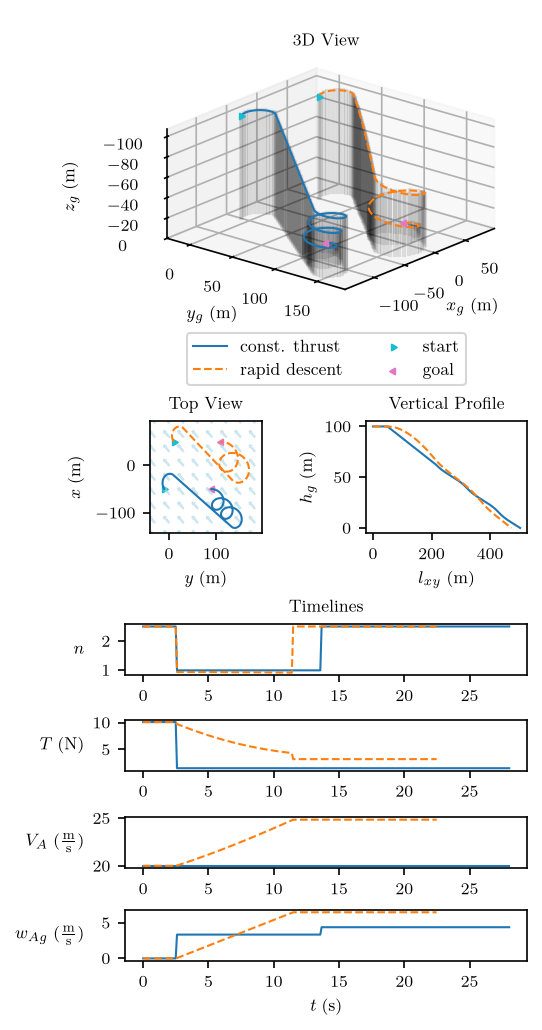

In [84]:
# 3D Dubins path with rapid descent longitudinal maneuver over the linear segment

def plot_trochoid_path_3D_rapid_descent():
    ac = get_aircraft_model()

    airspeed = 20
    wind_speed = 5
    wind_dir = -math.pi*0.25
    turn_n_max = 2.5

    # Create a start and a set of goal points
    start = Sample3D(0, 0, -100, math.radians(-30))
    goal = Sample3D(0, 100, 0, math.radians(-90))
    path_type = "RSL"

    discr_paths = []

    x_offset = 50
    y_offset = 10
    path = get_trochoid_path_3D_longitudinal_transition(
        start_x=start.x_g + x_offset,
        start_y=start.y_g + y_offset,
        start_z=start.z_g,
        start_dir=start.chi,
        goal_x=goal.x_g + x_offset,
        goal_y=goal.y_g + y_offset,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=airspeed,
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type=path_type,
        ac=ac,
        thrust_constraint=lambda T: T > 0 and T < 30,
        transition_strategy="rapid_descent_fixed_length",
        # high_alt_strategy="periodic paths",
        high_alt_strategy="full turns",
        smooth_thrust=False)
    check.assertIsNotNone(
        path,
        msg=f"Failed to plan {path_type} path "
        f"from {start} to {goal}")
    path_discr = path.discretize()
    ac.fly_trajectory(path_discr)
    path_discr.check_kinematic_consistency(
        1, 1, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    # Check initial and final state
    check.assertAlmostEqual(path_discr.x0["x_g"], start.x_g + x_offset)
    check.assertAlmostEqual(
        path_discr.xf["x_g"], goal.x_g + x_offset, places=0)
    check.assertAlmostEqual(path_discr.x0["y_g"], start.y_g + y_offset)
    check.assertAlmostEqual(
        path_discr.xf["y_g"], goal.y_g + y_offset, places=0)
    check.assertAlmostEqual(path_discr.x0["z_g"], start.z_g)
    check.assertAlmostEqual(path_discr.xf["z_g"], goal.z_g, places=0)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.x0["chi"], start.chi)),
        0.0,
        places=2)
    check.assertAlmostEqual(
        abs(utils.angular_diff(path_discr.xf["chi"], goal.chi)),
        0.0,
        places=2)

    discr_paths.append(path_discr)

    # Plan constant thrust path for comparison
    shifted_initial_turn = LiftedSegment(
        copy.deepcopy(path.horiz_profile.segments[0]),
        copy.deepcopy(path.vert_profile.segments[0])).shift(
            0, x_g=-x_offset, y_g=-y_offset)
    # discr_paths.append(shifted_initial_turn.discretize())
    # ac.fly_trajectory(discr_paths[-1])
    path_const_thrust = get_trochoid_path_3D_const_thrust(
        start_x=shifted_initial_turn.xf["x_g"],
        start_y=shifted_initial_turn.xf["y_g"],
        start_z=shifted_initial_turn.xf["z_g"],
        start_dir=shifted_initial_turn.xf["chi"],
        goal_x=goal.x_g - x_offset,
        goal_y=goal.y_g - y_offset,
        goal_z=goal.z_g,
        goal_dir=goal.chi,
        airspeed=airspeed,
        turn_rate=None,
        turn_n_max=turn_n_max,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        path_type="LSL",
        ac=ac,
        thrust_constraint=lambda T: T > 0 and T < 15,
        high_alt_strategy="full turns",
    )
    path_const_thrust = Trajectory(
        [shifted_initial_turn, path_const_thrust])
    path_const_thrust_discr = path_const_thrust.discretize()
    ac.fly_trajectory(path_const_thrust_discr)
    # path_const_thrust_discr.df[["u_K_g", "v_K_g", "x_g", "y_g",
    #                             "chi"]].plot()
    # plotting.show()
    path_const_thrust_discr.check_kinematic_consistency(
        1, 0, 0, 1, raise_err=True, abs_err_threshold=1e-6)
    discr_paths.append(path_const_thrust_discr)

    # Plot the results
    plotting.configure(mode="latex", pageformat="IEEE_single_column")
    POIs = [
        dict(
            x_g=start.x_g - x_offset,
            y_g=start.y_g - y_offset,
            z_g=start.z_g,
            # chi=start.chi,
            label="start",
            s=10,
            color="tab:cyan",
            # style="go",
            marker=(3, 0, math.degrees(start.chi + math.pi))),
        dict(
            x_g=goal.x_g - x_offset,
            y_g=goal.y_g - y_offset,
            z_g=goal.z_g,
            # chi=goal.chi,
            label="goal",
            s=10,
            color="tab:pink",
            # style="gx",
            marker=(3, 0, math.degrees(goal.chi + math.pi))),
        dict(
            x_g=start.x_g + x_offset,
            y_g=start.y_g + y_offset,
            z_g=start.z_g,
            # chi=start.chi,
            s=10,
            color="tab:cyan",
            # style="go",
            marker=(3, 0, math.degrees(start.chi + math.pi))),
        dict(
            x_g=goal.x_g + x_offset,
            y_g=goal.y_g + y_offset,
            z_g=goal.z_g,
            # chi=goal.chi,
            s=10,
            color="tab:pink",
            # style="gx",
            marker=(3, 0, math.degrees(goal.chi + math.pi)))
    ]

    fig, ax = plotting.plot_ref_trajectory(
        paths={
            "const. thrust": discr_paths[1].df,
            "rapid descent": discr_paths[0].df,
        },
        # paths=[p.df for p in discr_paths],
        POIs=POIs,
        s_col=None,
        wind_speed=wind_speed,
        wind_dir=wind_dir,
        timelines=["n", "T", "V_A", "w_A_g"])
    # ax["T"].set_ylim(-1, 5)

    if SAVE_PLOTS:
        fig.canvas.draw()
        fig.savefig("trochoid_path_csc3d_rapid_descent.pdf")
        if CROP_PLOTS:
            subprocess.run(
                [
                    "pdfcrop", "--margins", "0 0 0 0",
                    "trochoid_path_csc3d_rapid_descent.pdf",
                    "trochoid_path_csc3d_rapid_descent.cropped.pdf"
                ],
                check=True)

plt.close("all")
plot_trochoid_path_3D_rapid_descent()
plt.show()

## Chapter 2 - Runtime Benchmarks

Benchmark, analyze and report runtime of various solvers with randomized test sets.

A note on running this on modern CPUs with thermal/load management (i.e. on laptops): Always run benchmarks with disabled CPU turbo boost.

On Ubuntu, this can be achieved with:
```
echo 1 | sudo tee /sys/devices/system/cpu/intel_pstate/no_turbo
sudo cpupower frequency-set -g performance
```
Afterwards, revert to powersave mode:
```
echo 0 | sudo tee /sys/devices/system/cpu/intel_pstate/no_turbo
sudo cpupower frequency-set -g powersave
```
Monitor/verfify with:
```
sudo cpupower frequency-info
watch -n 1 grep \"cpu MHz\" /proc/cpuinfo
```

In [85]:
# Imports and configuration

import matplotlib.pyplot as plt
from IPython.display import display

# Import the test modules for the solvers
import tests.solver.test_dubins_path as test_dubins
import tests.solver.test_trochoid_path as test_trochoid

# Convenience aliases for the TestCase classes
DubinsPathTests = test_dubins.DubinsPathTests
TrochoidPathTests = test_trochoid.TrochoidPathTests

print("Imported test modules OK")

Imported test modules OK


In [86]:
# Benchmark of 2D Dubins path 

test_dubins.NUM_CASES_CSC_BENCHMARK = 1000
tc = test_dubins.DubinsPathTests()
tc.setUp()
tc.test_csc_benchmark()

Running benchmark: Benchmark for CSC 2D Dubins paths


Benchmark for CSC 2D Dubins paths: 100%|██████████| 1000/1000 [00:07<00:00, 128.37it/s]

Results of benchmark in 1000x1 runs:
    min: 0.000005 s
    max: 0.013080 s
   mean: 0.007599 s
 median: 0.007298 s
No traces logged to report


In [87]:
# Benchmark of 3D Dubins path with circular turns and constant vertical speed
# - with unconstrained vertical speed
# - with constrained vertical speed

test_dubins.NUM_CASES_CSC3D_BENCHMARK = 1000
tc = test_dubins.DubinsPathTests()
tc.setUp()
tc.test_csc3d_benchmark()

test_dubins.NUM_CASES_CSC3D_CONST_VS_BENCHMARK = 1000
tc = test_dubins.DubinsPathTests()
tc.setUp()
tc.test_csc3d_constrained_vert_speed_benchmark()

Running benchmark: Benchmark for CSC 3D Dubins Airplane paths


Benchmark for CSC 3D Dubins Airplane paths: 100%|██████████| 1000/1000 [00:40<00:00, 24.71it/s]


Results of benchmark in 1000x1 runs:
    min: 0.021209 s
    max: 0.092412 s
   mean: 0.040054 s
 median: 0.036825 s
Report over all traces:
  dubins_csc3D: acc. time=40.023565, count=1000
    success: 100.0% true, 0.0% false, n=1000
    iterations: 2.000 < 2.058 | 2.000 < 3.000, n=1000
    n_passes: 2.000 < 2.058 | 2.000 < 3.000, n=1000
    start_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
    end_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
Running benchmark: Benchmark for CSC 3D Dubins Airplane paths - randomized test set with vertical speed constraint


Benchmark for CSC 3D Dubins Airplane paths - randomized test set with vertical speed constraint: 100%|██████████| 1000/1000 [01:19<00:00, 12.59it/s]

Results of benchmark in 1000x1 runs:
    min: 0.021105 s
    max: 0.450712 s
   mean: 0.078966 s
 median: 0.044626 s
Report over all traces:
  dubins_csc3D: acc. time=78.934986, count=1000
    success: 100.0% true, 0.0% false, n=1000
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=1000
    n_passes: 2.000 < 4.127 | 2.000 < 23.000, n=1000
    start_rounds: 0.000 < 1.005 | 0.000 < 19.000, n=1000
    end_rounds: 0.000 < 1.122 | 0.000 < 21.000, n=1000


In [88]:
# Benchmark of 2D Dubins paths with trochoidal turns
# - symmetric case: constant turn rates and airspeeds
# - asymmetric case: distinct turn rates and airspeeds for initial and final turn

test_trochoid.NUM_CASES_CSC_BENCHMARK = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc_benchmark()

test_trochoid.NUM_CASES_CSCA_BENCHMARK = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csca_benchmark()

Running benchmark: Benchmark for CSC 2D Trochoid paths - randomized test set


Benchmark for CSC 2D Trochoid paths - randomized test set: 100%|██████████| 1000/1000 [00:04<00:00, 231.94it/s]


Results of benchmark in 1000x1 runs:
    min: 0.000671 s
    max: 0.031052 s
   mean: 0.004154 s
 median: 0.001077 s
Report over all traces:
  csc_newton: acc. time=3.222659, count=26190
    converged: 99.8% true, 0.2% false, n=26190
    guess: 0.000 < 28.181 | 21.592 < 166.936, n=26190
    iterations: 2.000 < 4.584 | 4.000 < 95.000, n=26138
    function_calls: 4.000 < 9.169 | 8.000 < 190.000, n=26138
Running benchmark: Benchmark for CSCA 2D Trochoid paths - randomized test set


Benchmark for CSCA 2D Trochoid paths - randomized test set: 100%|██████████| 1000/1000 [00:04<00:00, 236.52it/s]


Results of benchmark in 1000x1 runs:
    min: 0.000666 s
    max: 0.030266 s
   mean: 0.004057 s
 median: 0.000975 s
Report over all traces:
  csc_newton: acc. time=3.145226, count=26190
    converged: 99.8% true, 0.2% false, n=26190
    guess: 0.000 < 28.181 | 21.592 < 166.936, n=26190
    iterations: 2.000 < 4.584 | 4.000 < 95.000, n=26138
    function_calls: 4.000 < 9.169 | 8.000 < 190.000, n=26138


In [89]:
# Benchmark of 3D Dubins path with trochoidal turns and constant vertical speed
# - vertical speed unconstrained
# - vertical speed constrained with periodic paths for high-altitude cases
# - vertical speed constrained with full turns for high-altitude cases

test_trochoid.NUM_CASES_CSC3D_CONST_VS_BENCHMARK = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_vert_speed_benchmark()

Running benchmark: Testing CSC3D trochoid paths with unconstrained constant vertical speed - randomized test set


Testing CSC3D trochoid paths with unconstrained constant vertical speed - randomized test set: 100%|██████████| 1000/1000 [00:19<00:00, 50.87it/s]


Results of benchmark in 1000x1 runs:
    min: 0.003382 s
    max: 0.053705 s
   mean: 0.019243 s
 median: 0.028111 s
Report over all traces:
  trochoid_CSC3D_const_vert_speed: acc. time=15.557755, count=1000
    success: 100.0% true, 0.0% false, n=1000
    start_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
    end_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
    iterations: 2.000 < 2.077 | 2.000 < 3.000, n=1000
    n_passes: 2.000 < 2.077 | 2.000 < 3.000, n=1000
  trochoid_CSC3D_const_vert_speed.csc_newton: acc. time=11.502032, count=112644
    converged: 100.0% true, 0.0% false, n=112644
    guess: 0.000 < 3.303 | 3.203 < 8.267, n=112644
    iterations: 1.000 < 3.871 | 4.000 < 17.000, n=112644
    function_calls: 2.000 < 7.741 | 8.000 < 34.000, n=112644
  csc_newton: acc. time=2.740366, count=27054
    converged: 100.0% true, 0.0% false, n=27054
    guess: 0.000 < 3.306 | 3.206 < 8.267, n=27054
    iterations: 1.000 < 3.871 | 4.000 < 17.000, n=27054
    function_calls: 2.000 < 7.743

Benchmark for CSC3D trochoid paths with constrained vertical speed, periodic paths - randomized test set: 100%|██████████| 1000/1000 [00:20<00:00, 47.65it/s]


Results of benchmark in 1000x1 runs:
    min: 0.003360 s
    max: 0.106217 s
   mean: 0.020607 s
 median: 0.029111 s
Report over all traces:
  trochoid_CSC3D_const_vert_speed: acc. time=16.824900, count=1000
    success: 100.0% true, 0.0% false, n=1000
    start_rounds: 0.000 < 0.056 | 0.000 < 4.000, n=1000
    end_rounds: 0.000 < 0.091 | 0.000 < 7.000, n=1000
    iterations: 2.000 < 2.030 | 2.000 < 3.000, n=1000
    n_passes: 2.000 < 2.177 | 2.000 < 9.000, n=1000
  trochoid_CSC3D_const_vert_speed.csc_newton: acc. time=12.083708, count=117936
    converged: 100.0% true, 0.0% false, n=117936
    guess: 0.000 < 3.317 | 3.223 < 8.267, n=117936
    iterations: 1.000 < 3.872 | 4.000 < 17.000, n=117936
    function_calls: 2.000 < 7.745 | 8.000 < 34.000, n=117936
  csc_newton: acc. time=2.750871, count=27054
    converged: 100.0% true, 0.0% false, n=27054
    guess: 0.000 < 3.309 | 3.213 < 8.267, n=27054
    iterations: 1.000 < 3.874 | 4.000 < 17.000, n=27054
    function_calls: 2.000 < 7.747

Benchmark for CSC3D trochoid paths with constrained vertical speed, full turns - randomized test set: 100%|██████████| 1000/1000 [00:21<00:00, 47.26it/s]


Results of benchmark in 1000x1 runs:
    min: 0.003357 s
    max: 0.173231 s
   mean: 0.020868 s
 median: 0.029276 s
Report over all traces:
  trochoid_CSC3D_const_vert_speed: acc. time=17.123094, count=1000
    success: 100.0% true, 0.0% false, n=1000
    start_rounds: 0.000 < 0.076 | 0.000 < 6.000, n=1000
    end_rounds: 0.000 < 0.143 | 0.000 < 15.000, n=1000
    iterations: 2.000 < 2.030 | 2.000 < 3.000, n=1000
    n_passes: 2.000 < 2.249 | 2.000 < 17.000, n=1000
  trochoid_CSC3D_const_vert_speed.csc_newton: acc. time=12.390341, count=121392
    converged: 100.0% true, 0.0% false, n=121392
    guess: 0.000 < 3.311 | 3.215 < 8.267, n=121392
    iterations: 1.000 < 3.875 | 4.000 < 48.000, n=121388
    function_calls: 2.000 < 7.749 | 8.000 < 96.000, n=121388
  csc_newton: acc. time=2.750737, count=27054
    converged: 100.0% true, 0.0% false, n=27054
    guess: 0.000 < 3.308 | 3.213 < 8.267, n=27054
    iterations: 1.000 < 3.873 | 4.000 < 17.000, n=27051
    function_calls: 2.000 < 7.7

In [90]:
# Benchmark of 3D Dubins path with trochoidal turns and constant and constrained thrust
# - with periodic paths for high-altitude cases
# - with full turns for high-altitude cases

test_trochoid.NUM_CASES_CSC3D_CONST_THRUST_BENCHMARK = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_thrust_benchmark()

Running benchmark: Benchmark for CSC3D trochoid paths with constant thrust and periodic paths - randomized test set


Benchmark for CSC3D trochoid paths with constant thrust and periodic paths - randomized test set: 100%|██████████| 1000/1000 [02:57<00:00,  5.62it/s]


Results of benchmark in 1000x1 runs:
    min: 0.069386 s
    max: 1.046753 s
   mean: 0.170969 s
 median: 0.145940 s
Report over all traces:
  trochoid_CSC3D_const_thrust_v2.thrust_iteration: acc. time=166.930008, count=1076
    success: 100.0% true, 0.0% false, n=1076
    iterations: 1.000 < 5.908 | 6.000 < 30.000, n=1076
  trochoid_CSC3D_const_thrust_v2: acc. time=170.821662, count=1000
    start_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
    end_rounds: 0.000 < 0.076 | 0.000 < 9.000, n=1000
    n_passes: 1.000 < 1.076 | 1.000 < 10.000, n=1000
    success: 100.0% True, n=1000
  trochoid_CSC3D_const_thrust_v2.thrust_iteration.csc_newton: acc. time=17.286501, count=168426
    converged: 100.0% true, 0.0% false, n=168426
    guess: 0.000 < 3.189 | 3.076 < 8.267, n=168426
    iterations: 1.000 < 3.863 | 4.000 < 29.000, n=168426
    function_calls: 2.000 < 7.725 | 8.000 < 58.000, n=168426
  trochoid_CSC3D_const_thrust_v2.csc_newton: acc. time=2.775724, count=27054
    converged: 100.0%

Benchmark for CSC3D trochoid paths with constant thrust and full turns - randomized test set: 100%|██████████| 1000/1000 [02:57<00:00,  5.63it/s]


Results of benchmark in 1000x1 runs:
    min: 0.068205 s
    max: 0.956367 s
   mean: 0.170412 s
 median: 0.146604 s
Report over all traces:
  trochoid_CSC3D_const_thrust_v2.thrust_iteration: acc. time=166.401877, count=1097
    success: 100.0% true, 0.0% false, n=1097
    iterations: 1.000 < 5.841 | 6.000 < 30.000, n=1097
  trochoid_CSC3D_const_thrust_v2: acc. time=170.268066, count=1000
    start_rounds: 0.000 < 0.000 | 0.000 < 0.000, n=1000
    end_rounds: 0.000 < 0.097 | 0.000 < 12.000, n=1000
    n_passes: 1.000 < 1.097 | 1.000 < 13.000, n=1000
    success: 100.0% True, n=1000
  trochoid_CSC3D_const_thrust_v2.thrust_iteration.csc_newton: acc. time=17.316992, count=168642
    converged: 100.0% true, 0.0% false, n=168642
    guess: 0.000 < 3.188 | 3.076 < 8.267, n=168642
    iterations: 1.000 < 3.862 | 4.000 < 29.000, n=168642
    function_calls: 2.000 < 7.724 | 8.000 < 58.000, n=168642
  trochoid_CSC3D_const_thrust_v2.csc_newton: acc. time=2.768949, count=27054
    converged: 100.0

In [91]:
# Benchmark of 3D Dubins path with rapid descent longitudinal maneuver over linear segment
# - with fixed final altitude and periodic paths for high-altitude cases
# - with fixed final altitude and full turns for high-altitude cases
# - with free final altitude

test_trochoid.NUM_CASES_CSC3D_RAPID_DESCENT_BENCHMARK = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_rapid_descent_benchmark()

Running benchmark: Benchmark of CSC3D trochoid paths with rapid descent transition, periodic paths - randomized test set


Benchmark of CSC3D trochoid paths with rapid descent transition, periodic paths - randomized test set: 100%|██████████| 1000/1000 [05:57<00:00,  2.80it/s]


Results of benchmark in 1000x1 runs:
    min: 0.159501 s
    max: 0.904319 s
   mean: 0.344387 s
 median: 0.313770 s
Report over all traces:
  start_end_rounds_iteration.horiz_path.csc_newton: acc. time=7.078185, count=70200
    converged: 100.0% true, 0.0% false, n=70200
    guess: 0.000 < 3.469 | 3.407 < 8.266, n=70200
    iterations: 1.000 < 3.884 | 4.000 < 14.000, n=70200
    function_calls: 2.000 < 7.769 | 8.000 < 28.000, n=70200
  start_end_rounds_iteration.horiz_path: acc. time=45.706200, count=5562
    success: 100.0% true, 0.0% false, n=5562
  start_end_rounds_iteration.final_airspeed_iteration: acc. time=32.194301, count=4562
    success: 100.0% true, 0.0% false, n=4562
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=4562
  start_end_rounds_iteration.bisect_gamma_A_for_final_alt.final_airspeed_iteration: acc. time=265.452469, count=42761
    success: 100.0% true, 0.0% false, n=42761
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=42761
  start_end_rounds_iteration.bisect_ga

Benchmark of CSC3D trochoid paths with rapid descent transition, full turns - randomized test set: 100%|██████████| 1000/1000 [05:37<00:00,  2.97it/s]


Results of benchmark in 1000x1 runs:
    min: 0.159736 s
    max: 0.984934 s
   mean: 0.323987 s
 median: 0.310872 s
Report over all traces:
  start_end_rounds_iteration.horiz_path.csc_newton: acc. time=8.407847, count=83322
    converged: 100.0% true, 0.0% false, n=83322
    guess: 0.000 < 3.461 | 3.387 < 8.266, n=83322
    iterations: 1.000 < 3.896 | 4.000 < 14.000, n=83322
    function_calls: 2.000 < 7.792 | 8.000 < 28.000, n=83322
  start_end_rounds_iteration.horiz_path: acc. time=45.976764, count=6005
    success: 100.0% true, 0.0% false, n=6005
  start_end_rounds_iteration.final_airspeed_iteration: acc. time=32.691297, count=5005
    success: 100.0% true, 0.0% false, n=5005
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=5005
  start_end_rounds_iteration.bisect_gamma_A_for_final_alt.final_airspeed_iteration: acc. time=244.356980, count=43036
    success: 100.0% true, 0.0% false, n=43036
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=43036
  start_end_rounds_iteration.bisect_ga

Benchmark of CSC3D trochoid paths with rapid descent transition, free final altitutde - randomized test set: 100%|██████████| 1000/1000 [00:43<00:00, 23.08it/s]


Results of benchmark in 1000x1 runs:
    min: 0.027218 s
    max: 0.135011 s
   mean: 0.041601 s
 median: 0.038801 s
Report over all traces:
  start_end_rounds_iteration.horiz_path.csc_newton: acc. time=2.607731, count=25920
    converged: 100.0% true, 0.0% false, n=25920
    guess: 0.000 < 3.313 | 3.228 < 8.266, n=25920
    iterations: 1.000 < 3.880 | 4.000 < 14.000, n=25920
    function_calls: 2.000 < 7.760 | 8.000 < 28.000, n=25920
  start_end_rounds_iteration.horiz_path: acc. time=27.143125, count=3205
    success: 100.0% true, 0.0% false, n=3205
  start_end_rounds_iteration.final_airspeed_iteration: acc. time=14.184680, count=2205
    success: 100.0% true, 0.0% false, n=2205
    iterations: 2.000 < 2.000 | 2.000 < 2.000, n=2205
  start_end_rounds_iteration.horiz_path.csca_newton: acc. time=18.134885, count=92610
    converged: 99.8% true, 0.2% false, n=92610
    guess: 0.620 < 3.367 | 3.285 < 7.233, n=92610
    iterations: 2.000 < 6.541 | 5.000 < 100.000, n=92438
    function_call

## Chapter 3 - Constraint Slack Analysis

Here, trajectories are generated using various solvers, evaluated numerically and checked against the constraints that the corresponding solver claims to satisfy. This is to ensure experimentally that constraints are satisfied and to analyze the slack/margin towards the min./max. values. Ideally, slack should be close to zero at the minimum (not globally throughout all points of all trajectories) such that constraints can be set to represent the true physical limits and the system's performance is fully exploited.

In [92]:
# Slack towards vertical speed constraint for 3D Dubins path with circular turns

test_dubins.NUM_CASES_CSC3D_CONST_VS_RANDOM = 1000
tc = test_dubins.DubinsPathTests()
tc.setUp()
tc.test_csc3d_constrained_vert_speed_randomized()

Running test suite: Testing CSC 3D Dubins Airplane paths - randomized test set with vertical speed constraint


Testing CSC 3D Dubins Airplane paths - randomized test set with vertical speed constraint: 100%|██████████| 1000/1000 [02:04<00:00,  8.03it/s]


Max. load factor constraint (n <= 4) slack(min/median/max): 0.000112817 / 1.57927 / 2.99316; violating samples: 0/63824
Vertical speed constraint slack [m/s] (min/median/max): 0.00431106 / 2.57593 / 3.99877; violating samples: 0/596297


In [93]:
# Slack towards vertical speed constraint for 3D Dubins path with trochoidal turns

test_trochoid.NUM_CASES_CSC3D_CONST_VS_RANDOM = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_vert_speed_random()

Running test suite: Testing CSC3D trochoid paths with unconstrained constant vertical speed - randomized test set


Testing CSC3D trochoid paths with unconstrained constant vertical speed - randomized test set: 100%|██████████| 1000/1000 [01:31<00:00, 10.94it/s]


Max. load factor constraint (n <= 4) slack(min/median/max): -1.77636e-15 / 0 / 1.33227e-15; violating samples: 0/33363
Running test suite: Testing CSC3D trochoid paths with constrained vertical speed, periodic paths - randomized test set


Testing CSC3D trochoid paths with constrained vertical speed, periodic paths - randomized test set: 100%|██████████| 1000/1000 [01:33<00:00, 10.65it/s]


Vertical speed constraint (|w_A_g| <= 4 [m/s]) slack(min/median/max): 0.0039473 / 2.52745 / 3.99875; violating samples: 0/576934
Max. load factor constraint (n <= 4) slack(min/median/max): -1.77636e-15 / 0 / 1.33227e-15; violating samples: 0/38611
Running test suite: Testing CSC3D trochoid paths with constrained vertical speed, full turns - randomized test set


Testing CSC3D trochoid paths with constrained vertical speed, full turns - randomized test set: 100%|██████████| 1000/1000 [01:33<00:00, 10.69it/s]


Vertical speed constraint (|w_A_g| <= 4 [m/s]) slack(min/median/max): 6.30283e-05 / 2.52745 / 3.99875; violating samples: 0/576184
Max. load factor constraint (n <= 4) slack(min/median/max): -1.77636e-15 / 0 / 1.33227e-15; violating samples: 0/41047


In [94]:
# Slack towards thrust constraint for 3D Dubins path with trochoidal turns

test_trochoid.NUM_CASES_CSC3D_CONST_THRUST_RANDOM = 1000
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_thrust_random()

Running test suite: Test CSC3D trochoid paths with constant thrust and periodic paths - randomized test set


Test CSC3D trochoid paths with constant thrust and periodic paths - randomized test set: 100%|██████████| 1000/1000 [04:08<00:00,  4.02it/s]


Thrust constraint (T >= 0) slack (min/median/max): 0.000457764 / 7.82822 / 20.6593; violating samples: 0/572228
Thrust constraint (T <= 30) slack (min/median/max): 9.34067 / 22.1718 / 29.9995; violating samples: 0/572228
Max. load factor constraint (n <= 4) slack(min/median/max): -1.77636e-15 / 0 / 2.22045e-15; violating samples: 0/34974
Running test suite: Test CSC3D trochoid paths with constant thrust and full turns - randomized test set


Test CSC3D trochoid paths with constant thrust and full turns - randomized test set: 100%|██████████| 1000/1000 [04:07<00:00,  4.05it/s]


Thrust constraint (T >= 0) slack (min/median/max): 0.0169373 / 7.86392 / 20.6593; violating samples: 0/571415
Thrust constraint (T <= 30) slack (min/median/max): 9.34067 / 22.1361 / 29.9831; violating samples: 0/571415
Max. load factor constraint (n <= 4) slack(min/median/max): -1.77636e-15 / 0 / 2.22045e-15; violating samples: 0/35537


## Chapter 4 - Experimental Convergence Analysis

This is an experimental setup using the `htrace` module to analyze solver-internal loops and iteration counts as well as runtimes. The motivation is to understand convergence rates and interaction of nested loops in more depth.

In [95]:
# Convergence analysis for 3D Dubins path solver with circular turns and constrained vertical speed

test_dubins.NUM_CASES_CSC3D_CONST_VS_CONVERGENCE = 1000
test_dubins.DEBUG_PLOTS = False
tc = test_dubins.DubinsPathTests()
tc.setUp()
tc.test_csc3d_constrained_vert_speed_convergence()

Collect traces for CSC 3D Dubins Airplane paths - randomized test set with vertical speed constraint: 100%|██████████| 1000/1000 [01:16<00:00, 13.12it/s]

=== TRACES SUMMARY ===
     trace_id path_type   airspeed  wind_speed      xy_dist      z_dist
0           0       LSL  16.556440    3.950709  1449.136451   -5.009197
1           1       LSL  17.313081    0.339282  1415.560860 -195.728500
2           2       LSL  22.922511    0.833085  1380.025123   15.542457
3           3       RSR  18.832469    6.544885   954.516443    4.667608
4           4       RSR  20.573311    1.024906   923.527322  -39.552200
..        ...       ...        ...         ...          ...         ...
995       995       RSL  24.953448    5.873897   449.954017  102.200928
996       996       RSR  23.494258    7.335752  1747.020710   33.891610
997       997       LSR  20.276207    1.141042  1361.691812   23.506631
998       998       LSR  18.676252    2.594403  1171.014324   13.879282
999       999       LSR  21.107480    1.715784   324.571079   41.922676

[1000 rows x 6 columns]
=== RT TRACES ===
     trace_id  span_id          span  duration  self_duration  success

In [96]:
# Convergence analysis for 3D Dubins path solver with trochoidal turns and constrained vertical speed

test_trochoid.NUM_CASES_CSC3D_CONST_VS_CONVERGENCE = 1000
test_trochoid.DEBUG_PLOTS = False
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_vert_speed_convergence()

Collect traces for CSC 3D trochoid paths - randomized test set with vertical speed constraint: 100%|██████████| 1000/1000 [00:23<00:00, 41.75it/s]


=== TRACES SUMMARY ===
     trace_id path_type   airspeed  wind_speed      xy_dist      z_dist
0           0       LSL  16.556440    3.950709  1449.136451   -5.009197
1           1       LSL  17.313081    0.339282  1415.560860 -195.728500
2           2       LSL  22.922511    0.833085  1380.025123   15.542457
3           3       RSR  18.832469    6.544885   954.516443    4.667608
4           4       RSR  20.573311    1.024906   923.527322  -39.552200
..        ...       ...        ...         ...          ...         ...
995       995       RSL  24.953448    5.873897   449.954017  102.200928
996       996       RSR  23.494258    7.335752  1747.020710   33.891610
997       997       LSR  20.276207    1.141042  1361.691812   23.506631
998       998       LSR  18.676252    2.594403  1171.014324   13.879282
999       999       LSR  21.107480    1.715784   324.571079   41.922676

[1000 rows x 6 columns]
=== RT TRACES ===
        trace_id  span_id                             span  duration  

Collect traces for CSC 3D trochoid paths with constrained vertical speed, full turns - randomized test set: 100%|██████████| 1000/1000 [00:24<00:00, 40.26it/s]


=== TRACES SUMMARY ===
     trace_id path_type   airspeed  wind_speed      xy_dist      z_dist
0           0       LSL  16.556440    3.950709  1449.136451   -5.009197
1           1       LSL  17.313081    0.339282  1415.560860 -195.728500
2           2       LSL  22.922511    0.833085  1380.025123   15.542457
3           3       RSR  18.832469    6.544885   954.516443    4.667608
4           4       RSR  20.573311    1.024906   923.527322  -39.552200
..        ...       ...        ...         ...          ...         ...
995       995       RSL  24.953448    5.873897   449.954017  102.200928
996       996       RSR  23.494258    7.335752  1747.020710   33.891610
997       997       LSR  20.276207    1.141042  1361.691812   23.506631
998       998       LSR  18.676252    2.594403  1171.014324   13.879282
999       999       LSR  21.107480    1.715784   324.571079   41.922676

[1000 rows x 6 columns]
=== RT TRACES ===
        trace_id  span_id                             span  duration  

In [97]:
# Convergence analysis for 3D Dubins path solver with trochoidal turns and constrained thrust

test_trochoid.NUM_CASES_CSC3D_CONST_VS_CONVERGENCE = 1000
test_trochoid.DEBUG_PLOTS = False
tc = test_trochoid.TrochoidPathTests()
tc.setUp()
tc.test_csc3d_const_vert_speed_convergence()

Collect traces for CSC 3D trochoid paths - randomized test set with vertical speed constraint: 100%|██████████| 1000/1000 [00:24<00:00, 40.86it/s]


=== TRACES SUMMARY ===
     trace_id path_type   airspeed  wind_speed      xy_dist      z_dist
0           0       LSL  16.556440    3.950709  1449.136451   -5.009197
1           1       LSL  17.313081    0.339282  1415.560860 -195.728500
2           2       LSL  22.922511    0.833085  1380.025123   15.542457
3           3       RSR  18.832469    6.544885   954.516443    4.667608
4           4       RSR  20.573311    1.024906   923.527322  -39.552200
..        ...       ...        ...         ...          ...         ...
995       995       RSL  24.953448    5.873897   449.954017  102.200928
996       996       RSR  23.494258    7.335752  1747.020710   33.891610
997       997       LSR  20.276207    1.141042  1361.691812   23.506631
998       998       LSR  18.676252    2.594403  1171.014324   13.879282
999       999       LSR  21.107480    1.715784   324.571079   41.922676

[1000 rows x 6 columns]
=== RT TRACES ===
        trace_id  span_id                             span  duration  

Collect traces for CSC 3D trochoid paths with constrained vertical speed, full turns - randomized test set: 100%|██████████| 1000/1000 [00:24<00:00, 40.42it/s]


=== TRACES SUMMARY ===
     trace_id path_type   airspeed  wind_speed      xy_dist      z_dist
0           0       LSL  16.556440    3.950709  1449.136451   -5.009197
1           1       LSL  17.313081    0.339282  1415.560860 -195.728500
2           2       LSL  22.922511    0.833085  1380.025123   15.542457
3           3       RSR  18.832469    6.544885   954.516443    4.667608
4           4       RSR  20.573311    1.024906   923.527322  -39.552200
..        ...       ...        ...         ...          ...         ...
995       995       RSL  24.953448    5.873897   449.954017  102.200928
996       996       RSR  23.494258    7.335752  1747.020710   33.891610
997       997       LSR  20.276207    1.141042  1361.691812   23.506631
998       998       LSR  18.676252    2.594403  1171.014324   13.879282
999       999       LSR  21.107480    1.715784   324.571079   41.922676

[1000 rows x 6 columns]
=== RT TRACES ===
        trace_id  span_id                             span  duration  